# Módulo 3 — Diferenciação e raízes unitárias

## Seção 5 — Sobrediferenciação e critérios para decidir quando diferenciar

**Estado:** versão didática para revisão. **Integração:** matemática, exemplos, Python, interpretação e exercícios no mesmo texto. **Pré-requisitos:** Módulo 1 (momentos, estacionariedade e ruído branco); Módulo 2 (tendência, sazonalidade); Módulo 3, §§1–4 (operador de atraso, diferenças, integração, ADF e KPSS).

**Referências e escopo.** Morettin e Toloi, *Análise de Séries Temporais: modelos lineares univariados*, v. 1, 3ª ed., §1.4, pp. 5–6 (conceito e fórmulas de diferenças), e Apêndice B, §§B.1–B.3, pp. 411–417 (raízes unitárias e procedimentos de teste), fundamentam os tópicos já introduzidos nas seções anteriores. O mapeamento das videoaulas identifica *Aplicação de Diferenças*, *Aula 4 — ACF, CCF, Diferenciação e Retornos* e *Aula 7 — ARMA, ARIMA e Testes de Estacionariedade*. **As deduções sobre sobrediferenciação, protocolos de decisão e experimentos numéricos desta seção são complementações didáticas originais**, não transcrições atribuídas a essas páginas.

### Objetivos de aprendizagem

Ao concluir, você deverá distinguir diferenciação necessária e excessiva; demonstrar como a primeira diferença altera a autocovariância; identificar o surgimento de autocorrelação negativa ao diferenciar ruído branco; distinguir estacionarização por remoção de tendência determinística de diferenciação de uma raiz unitária; interpretar gráficos e resultados dos testes ADF/KPSS como evidências falíveis; e selecionar um procedimento de transformação sem vazamento de informações futuras.

### 1. Motivação — por que mais diferenças não significam melhor resultado?

A operação de primeira diferença é

$$
\Delta Z_t=(1-B)Z_t=Z_t-Z_{t-1},
$$

em que $B Z_t=Z_{t-1}$. Como visto nas Seções 1–3, diferenciar pode remover uma tendência linear determinística **ou** eliminar uma raiz unitária. Esses efeitos não são equivalentes. Repetir a diferenciação sem justificativa pode criar dependência artificial, aumentar a irregularidade observada e descartar informação útil do nível da série.

**Definição operacional (complementação didática).** Chamaremos de *sobrediferenciação* a aplicação de uma ordem de diferença maior do que a necessária para obter a estrutura estacionária adequada ao modelo escolhido. O conceito é dependente da classe de modelos e do objetivo da análise: uma transformação pode ser desnecessária para um modelo estocástico e ainda ter utilidade em outro procedimento descritivo, desde que justificada.

A ordem de integração $d$ de um processo $I(d)$ é uma propriedade do processo e de suas hipóteses, não o resultado de aumentar $d$ até um gráfico parecer “ruidoso”.

### 2. Exemplo matemático central: diferenciar um ruído branco

Considere $\{\varepsilon_t\}$ com

$$
E[\varepsilon_t]=0,\qquad
\mathrm{Var}(\varepsilon_t)=\sigma^2>0,
$$

$$
\mathrm{Cov}(\varepsilon_t,\varepsilon_s)=0\quad (t\ne s).
$$

Essa sequência já é fracamente estacionária. Defina a série desnecessariamente diferenciada

$$
Y_t=\Delta\varepsilon_t=\varepsilon_t-\varepsilon_{t-1}.
$$

**Passo 1 — média.** Por linearidade,

$$
E[Y_t]=E[\varepsilon_t]-E[\varepsilon_{t-1}]=0.
$$

**Passo 2 — variância.** Pela identidade $\mathrm{Var}(A-B)=\mathrm{Var}(A)+\mathrm{Var}(B)-2\mathrm{Cov}(A,B)$,

$$
\begin{aligned}
\mathrm{Var}(Y_t)
&=\sigma^2+\sigma^2-2\cdot0\\
&=2\sigma^2.
\end{aligned}
$$

**Passo 3 — autocovariância na defasagem 1.** Usando a bilinearidade da covariância,

$$
\begin{aligned}
\mathrm{Cov}(Y_t,Y_{t-1})
&=\mathrm{Cov}(\varepsilon_t-\varepsilon_{t-1},
                  \varepsilon_{t-1}-\varepsilon_{t-2})\\
&=0-0-\mathrm{Var}(\varepsilon_{t-1})+0\\
&=-\sigma^2.
\end{aligned}
$$

**Passo 4 — outras defasagens.** Para $|h|\ge2$, as duas diferenças não compartilham nenhum termo de inovação; as covariâncias cruzadas são nulas. Logo,

$$
\boxed{
\gamma_Y(h)=
\begin{cases}
2\sigma^2,&h=0,\\
-\sigma^2,&|h|=1,\\
0,&|h|\ge2.
\end{cases}}
$$

Dividindo pela variância $\gamma_Y(0)=2\sigma^2$, temos

$$
\boxed{\rho_Y(1)=-\frac12,\qquad \rho_Y(h)=0\ (|h|\ge2).}
$$

**Interpretação:** $Y_t$ continua fracamente estacionário, mas deixa de ser ruído branco, porque observações consecutivas possuem covariância negativa. Ao diferenciar, criamos uma dependência linear onde antes não havia autocorrelação. A expressão $Y_t=(1-B)\varepsilon_t$ caracteriza um MA(1) com coeficiente $-1$ segundo a convenção $\varepsilon_t+\theta\varepsilon_{t-1}$. Esse MA(1) está na fronteira da invertibilidade, que será estudada posteriormente.

**Atenção:** esse resultado não depende de normalidade ou de independência completa; bastam ruído branco de segunda ordem e variância finita.

### 3. Relação geral entre autocovariâncias antes e depois da diferença

Se $X_t$ é fracamente estacionário com função de autocovariância $\gamma_X(h)$, considere $Y_t=X_t-X_{t-1}$. Então

$$
\begin{aligned}
\gamma_Y(h)
&=\mathrm{Cov}(X_t-X_{t-1},X_{t+h}-X_{t+h-1})\\
&=\gamma_X(h)-\gamma_X(h-1)-\gamma_X(h+1)+\gamma_X(h)\\
&=\boxed{2\gamma_X(h)-\gamma_X(h-1)-\gamma_X(h+1)}.
\end{aligned}
$$

Essa identidade explica, em nível teórico, por que a diferenciação altera a dependência. Para $h=0$,

$$
\gamma_Y(0)=2\bigl[\gamma_X(0)-\gamma_X(1)\bigr].
$$

Portanto, a variância depois da diferença pode aumentar ou diminuir, dependendo da autocorrelação na primeira defasagem. **Não é correto afirmar que diferenciar sempre reduz a variância.**

### 4. Duas séries semelhantes, efeitos distintos da primeira diferença

Retome, com inovações independentes e de variância $\sigma^2$:

$$
X_t=\alpha+\beta t+\varepsilon_t
$$

(tendência determinística) e

$$
W_t=W_{t-1}+\beta+\varepsilon_t
$$

(passeio aleatório com deriva).

Aplicando $\Delta$:

$$
\boxed{\Delta X_t=\beta+\varepsilon_t-\varepsilon_{t-1}},
$$

$$
\boxed{\Delta W_t=\beta+\varepsilon_t}.
$$

Apesar de os dois processos terem tendência linear na média, suas primeiras diferenças são diferentes: a primeira apresenta autocovariância $-\sigma^2$ na defasagem 1; a segunda, sob inovações de ruído branco, tem covariância zero nas defasagens não nulas.

Há uma alternativa importante para $X_t$: se $\alpha$ e $\beta$ forem conhecidos, retirar $\alpha+\beta t$ deixa exatamente $\varepsilon_t$, sem introduzir dependência adicional. Com parâmetros estimados, será necessário analisar a incerteza do ajuste e, em tarefas preditivas, estimá-los somente na amostra de treinamento.

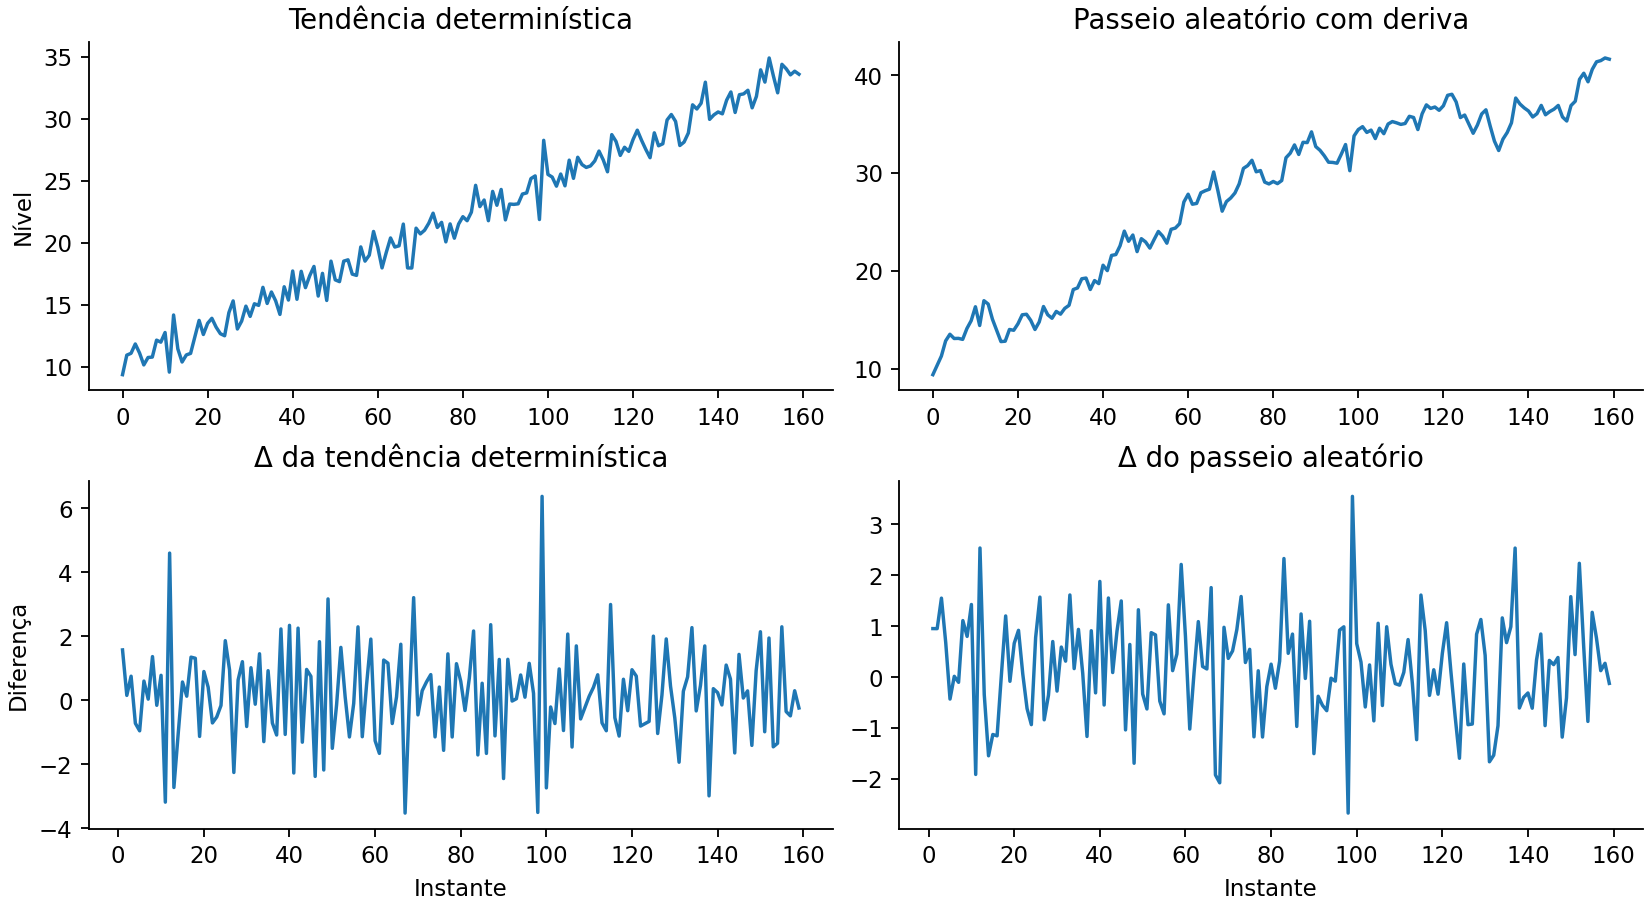

*Figura 1. Trajetórias sintéticas geradas com as mesmas inovações. As diferenças apresentam mecanismos distintos, mesmo quando ambas as séries originais crescem em média. O gráfico não demonstra a natureza dos processos: ela decorre das equações e hipóteses estabelecidas.*

### 5. Exemplo computacional: ruído branco diferenciado

Para permitir comparação com a dedução, usaremos `numpy.random.default_rng()` com semente fixa. `np.diff(x)` calcula $x_t-x_{t-1}$ para elementos consecutivos e devolve um vetor com comprimento uma unidade menor. O código usa somente NumPy e Matplotlib.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(20261116)
n = 5000

# Ruído branco gaussiano apenas para a simulação.
# A dedução da seção não exige distribuição normal.
epsilon = rng.normal(loc=0.0, scale=1.0, size=n)
y = np.diff(epsilon)

# Estimativa convencional de autocorrelação com denominador
# comum. Aqui, a média é estimada da própria série y.
y_c = y - np.mean(y)
rho1 = np.sum(y_c[:-1] * y_c[1:]) / np.sum(y_c**2)

print(f"ACF estimada, defasagem 1: {rho1:.4f}")
print("Valor teórico: -0.5000")

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(epsilon[:100], label="Ruído branco")
ax.plot(np.arange(1, 100), y[:99], alpha=0.7,
        label="Primeira diferença")
ax.set(xlabel="Instante", ylabel="Valor",
       title="Diferenciação de ruído branco")
ax.legend()
ax.grid(alpha=0.25)
plt.show()


**Verificação executada.** Com a semente acima e NumPy instalado no ambiente de execução, obteve-se $\widehat\rho_Y(1)\approx-0{,}5116$, próximo de $-0{,}5$. A diferença decorre de amostragem finita; não é uma demonstração. Os detalhes das convenções amostrais de ACF ficarão no Módulo 4.

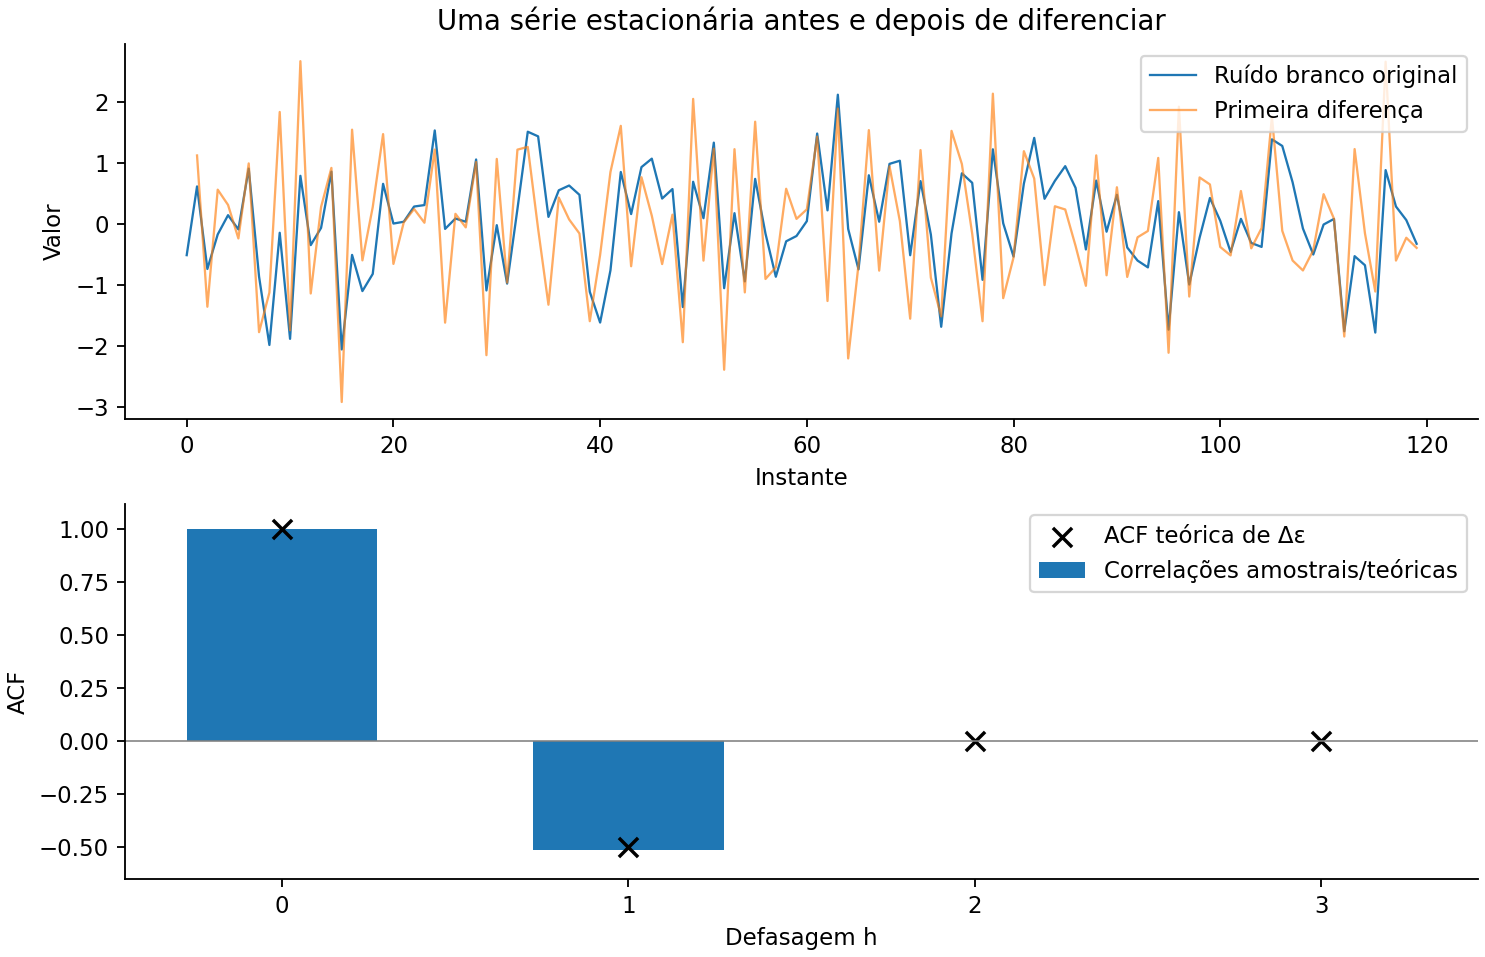

*Figura 2. Painel superior: parte das trajetórias simuladas de ruído branco e de sua primeira diferença. Painel inferior: autocorrelação na defasagem 1 próxima de $-0{,}5$. As defasagens 2 e 3 foram assinaladas em zero **como valores teóricos**, não como estimativas amostrais.*

### 6. Diferenças repetidas e sazonais: cuidado com a ordem

A segunda diferença é

$$
\Delta^2Z_t=Z_t-2Z_{t-1}+Z_{t-2}.
$$

Se $Z_t$ é $I(1)$ e $\Delta Z_t$ já é estacionário, uma segunda diferença pode levar ao problema da Seção 2 acima: diferenciar desnecessariamente o componente estacionário.

Analogamente, aplicar $(1-B^s)$ a uma série apenas porque há picos sazonais no gráfico pode ser inadequado: **sazonalidade determinística** pode ser modelada por indicadores ou termos harmônicos, sem exigir raiz unitária sazonal. Uma raiz unitária sazonal é uma hipótese dinâmica distinta.

O operador combinado $\Delta\Delta_s=(1-B)(1-B^s)$ exige atenção especial: pode eliminar componentes de frequência zero e sazonais, mas também pode sobrediferenciar. A escolha de $d$ e $D$ não deve ser automática.

### 7. Protocolo fundamentado para decidir se diferenciar

A decisão é uma sequência de evidências, não uma regra mecânica:

1. **Descrever a série e o processo proposto.** Identifique frequência de amostragem, irregularidades, tendência, sazonalidade e possíveis mudanças estruturais. Um gráfico sozinho não estabelece estacionariedade.
2. **Distinguir tipos de não estacionariedade.** Pergunte se há tendência determinística removível por regressão ou persistência compatível com raiz unitária; compare os resíduos conforme o modelo.
3. **Examinar diferenças de ordens candidatas.** Compare nível, $\Delta Z_t$ e, somente quando houver razão, $\Delta^2 Z_t$ ou $\Delta_s Z_t$, sempre anotando perdas de observações.
4. **Utilizar testes com a especificação correta.** No ADF, $H_0$ envolve raiz unitária; no KPSS, $H_0$ é estacionariedade em torno do nível ou da tendência escolhida. Não rejeitar uma hipótese não a comprova. As conclusões dependem de termos determinísticos, defasagens, amostra e outras suposições.
5. **Inspecionar a estrutura de dependência remanescente.** Autocorrelação negativa acentuada em $h=1$ após uma diferença pode alertar para sobrediferenciação, mas não é diagnóstico exclusivo.
6. **Confrontar modelos alternativos e propósito analítico.** Se o objetivo for previsão, faça ajustes e seleções utilizando apenas o período disponível na origem de cada previsão; compare erros em validação cronológica.

**Limitações importantes:** quebras estruturais podem confundir testes de raiz unitária; processos quase integrados podem apresentar baixa potência; fortes efeitos sazonais podem requerer testes especializados. Transformar não garante independência, normalidade ou desempenho preditivo.

### 8. Exercícios

**Conceitual.** (1) Explique por que uma primeira diferença não torna necessariamente a série “mais estacionária” quando ela já é ruído branco. (2) Uma sazonalidade anual fixa implica raiz unitária sazonal? Justifique.

**Matemático.** (3) Para ruído branco com $\sigma^2=9$, calcule $\mathrm{Var}(\Delta\varepsilon_t)$, $\mathrm{Cov}(\Delta\varepsilon_t,\Delta\varepsilon_{t-1})$ e $\rho(1)$. (4) Partindo da identidade para $\gamma_Y(h)$, verifique $\gamma_Y(0)$ no caso de um processo estacionário com $\gamma_X(0)=5$ e $\gamma_X(1)=3$.

**Programação.** (5) Altere `n` de 5.000 para 50, 500 e 20.000; compare as estimativas de $\rho(1)$ em várias sementes. (6) Simule $X_t=3+0{,}2t+\varepsilon_t$ e compare os resíduos após remoção da tendência conhecida com a primeira diferença; interprete o efeito na correlação de lag 1.

**Orientações selecionadas:** no exercício (3), a variância é $18$, a covariância de defasagem 1 é $-9$, e a correlação é $-1/2$. No exercício (4), $\gamma_Y(0)=2(5-3)=4$. Para o exercício (5), não espere aproximação monotônica do erro em cada realização; o erro flutua.

### 9. Síntese e referências

Diferenciar é uma transformação algébrica útil, mas não uma garantia de melhoria. Uma diferença desnecessária pode introduzir autocorrelação negativa e complicar o modelo. Para uma tendência determinística, retirar a componente ajustada e tomar diferenças são procedimentos diferentes; para um passeio aleatório, a primeira diferença recupera as inovações. Critérios de decisão devem combinar teoria, inspeção, testes com hipóteses explícitas e, em previsão, validação temporal.

**Fonte acadêmica principal consultada:** MORETTIN, P. A.; TOLOI, C. M. C. *Análise de séries temporais: modelos lineares univariados*. 3. ed., v. 1. São Paulo: Blucher, 2018, §1.4, pp. 5–6, e Apêndice B, pp. 411–417 (apoio aos conceitos de diferenciação e raiz unitária). **Complementações didáticas originais:** desenvolvimento das identidades de sobrediferenciação, exemplos, protocolo e códigos desta seção. **Mapeamento audiovisual:** `mapeamento-conteudos-series-temporais.md`, entradas *Aplicação de Diferenças*, *Aula 4* e *Aula 7*.

**Continuidade:** o Módulo 4 estudará formalmente as propriedades da função de autocovariância, retomada aqui apenas no nível necessário para compreender a sobrediferenciação.